# 03 · C · Tout générer, puis réduire

*Module 14 « Feature engineering & transformation » · TD du mercredi 21 octobre 2026 · environ 35 minutes en salle.*

### Ce qu'on fait

L'approche B part d'hypothèses métier. L'approche C fait l'inverse : on ne formule **aucune hypothèse**, on laisse
`PolynomialFeatures` fabriquer tous les carrés et tous les produits deux à deux des 14 numériques, on ajoute le
one-hot des catégorielles, et l'on obtient 470 colonnes. Puis on essaie les trois remèdes du cours 2 pour réduire :
**extraire** (ACP), **filtrer** (un score par colonne), **sélectionner en apprenant** (pénalité L1), avec le
**wrapper** en démonstration. On regarde ce que chaque méthode garde, ce qu'elle jette et ce qu'elle coûte.

### Les choix de cette approche

| Décision | Choix | Pourquoi |
|---|---|---|
| Créer | `PolynomialFeatures(degree=2, include_bias=False)` sur les 14 numériques brutes autorisées (`NUMERIQUES`) | toutes les interactions, sans hypothèse : la machine propose, la réduction tranchera |
| Échelle | médiane, puis `StandardScaler()` avant **et** après les produits | sans la première, `lead_time × adr` écraserait tout ; sans la seconde, les produits n'auraient plus la même échelle |
| Catégorielles | les 11 de `CATEGORIELLES` en one-hot (`min_frequency=20`, `handle_unknown="infrequent_if_exist"`), **non croisées** | comme dans l'approche A ; les croiser donnerait des dizaines de milliers de colonnes (on le calcule) |
| C1 · extraire | `PCA(n_components=0.95)` | le premier remède du cours 2 : garder 95 % de la variance avec moins d'axes |
| C2 · filtrer | `SelectKBest(f_classif, k=40)` | rapide, sans modèle : un score ANOVA par colonne |
| C3 · embedded | `SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.05, tol=1e-3, random_state=0))` | la pénalité L1 met des coefficients à zéro ; `tol=1e-3` tient le temps de calcul (section 7) |
| Wrapper | `SequentialFeatureSelector`, en démonstration, sur les 14 numériques seulement | sur 470 colonnes, il faudrait des dizaines de milliers d'entraînements (on le calcule) |
| Où réduire | dans le pipeline, juste après la génération | la réduction apprend : sur le train seulement, et de nouveau pour chaque modèle |

### Les outils utilisés

- `PolynomialFeatures` : les interactions et la formule p(p + 3)/2 (cours 1, slide 17).
- `SimpleImputer`, `StandardScaler`, `OneHotEncoder` : comme dans l'approche A (cours 1, slides 20 et 21 ; cours 2,
  slide 5).
- `ColumnTransformer`, `make_pipeline` : tout s'ajuste sur le train, réduction comprise (cours 2, slides 24 et 25).
- `PCA`, `explained_variance_ratio_`, `components_`, `inverse_transform` : extraire des axes (cours 2, slides 12
  à 16) ; le fléau de la dimension (cours 2, slide 11).
- `SelectKBest` avec `f_classif`, `mutual_info_classif` : les filtres (cours 2, slide 18).
- `cross_val_score` et le piège « sélectionner avant de valider » (cours 2, slide 23).
- `SequentialFeatureSelector` avec `TimeSeriesSplit` : le wrapper (cours 2, slides 19 et 20 ; cours 1, slide 9).
- `SelectFromModel` et `LogisticRegression(l1_ratio=1)` : l'embedded (cours 2, slide 21).
- Le paquet du TD : `fe_tp.donnees.charger` et `decouper`, `fe_tp.evaluation.evaluer` et `modeles`.

### Ce qu'on regarde à la fin

Un tableau des AUC (trois façons de réduire × modèles), à côté de deux repères sans réduction : les 365 colonnes
de l'approche A et les 470 colonnes générées. Deux questions : réduire garde-t-il l'essentiel ? Et les interactions
générées ont-elles servi à quelque chose ?

## 1. Charger et découper

Comme dans tous les notebooks : `charger()`, `decouper()` dans le temps, et les 25 colonnes brutes autorisées.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import (SelectFromModel, SelectKBest, SequentialFeatureSelector, f_classif,
                                       mutual_info_classif)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

from fe_tp.donnees import CATEGORIELLES, CIBLE, NUMERIQUES, charger, decouper
from fe_tp.evaluation import evaluer, modeles

In [2]:
df = charger()
train, test = decouper(df)
X_train, y_train = train[NUMERIQUES + CATEGORIELLES], train[CIBLE]
X_test, y_test = test[NUMERIQUES + CATEGORIELLES], test[CIBLE]
print("train :", X_train.shape, "· test :", X_test.shape)

train : (95190, 25) · test : (24018, 25)


95 190 réservations pour apprendre, 24 018 pour tester, et 25 colonnes : 14 numériques et 11 catégorielles. C'est
exactement le point de départ de l'approche A.

## 2. Générer toutes les interactions

Pour p variables, `PolynomialFeatures(degree=2)` fabrique les p variables d'origine, leurs p carrés et leurs
p(p − 1)/2 produits deux à deux : p(p + 3)/2 colonnes (cours 1, slide 17). `include_bias=False` retire la
colonne constante. On standardise **avant** les produits, sinon `lead_time × adr` (des centaines × des centaines)
écraserait tout, et **après**, car le produit de deux variables standardisées ne l'est plus. Les catégorielles
passent en one-hot, sans être croisées.

In [3]:
interactions = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             PolynomialFeatures(degree=2, include_bias=False), StandardScaler())
one_hot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)
genere = ColumnTransformer([("num", interactions, NUMERIQUES), ("cat", one_hot, CATEGORIELLES)],
                           verbose_feature_names_out=False)
Z_train = pd.DataFrame(genere.fit_transform(X_train), columns=genere.get_feature_names_out(), index=X_train.index)
colonnes_num = genere.named_transformers_["num"].get_feature_names_out()
print(Z_train.shape[1], "colonnes, dont", len(colonnes_num), "issues des 14 numériques")

470 colonnes, dont 119 issues des 14 numériques


14 × 17 / 2 = 119 : les 14 variables, leurs 14 carrés et 91 produits deux à deux. Avec les 351 colonnes one-hot,
on arrive à 470 colonnes, contre 365 pour l'approche A : 105 colonnes de plus, sans une seule idée métier.

In [4]:
list(colonnes_num[[0, 13, 14, 15, 118]])

['lead_time',
 'total_of_special_requests',
 'lead_time^2',
 'lead_time arrival_date_week_number',
 'total_of_special_requests^2']

Les noms se lisent ainsi : `^2` désigne un carré, un espace désigne un produit. `lead_time arrival_date_week_number`,
c'est le délai multiplié par la semaine d'arrivée : une interaction que personne n'a demandée, peut-être utile,
peut-être pas. C'est à la réduction d'en décider.

Et si l'on croisait **aussi** les colonnes one-hot ? On partirait alors des 365 colonnes de l'approche A : les 14
numériques et les 351 colonnes one-hot.

In [5]:
p = len(NUMERIQUES) + Z_train.shape[1] - len(colonnes_num)
nb_colonnes = p * (p + 3) // 2
print(p, "colonnes →", nb_colonnes, "colonnes, soit", round(nb_colonnes * len(X_train) * 8 / 1e9), "Go en mémoire")

365 colonnes → 67160 colonnes, soit 51 Go en mémoire


Croiser aussi les 351 colonnes one-hot donnerait 67 160 colonnes, soit 51 Go en mémoire pour le seul train : la
machine ne suit plus (cours 1, slide 17 : « croiser les variables, sans exploser »). Et la plupart de ces colonnes
seraient vides : le produit de `hotel_City Hotel` et de `hotel_Resort Hotel`, par exemple, vaut toujours 0. On ne
croise donc que les numériques.

Générer sans hypothèse produit aussi des **doublons**. On compte les paires très corrélées (|r| > 0,9, le repère
du cours 2, slide 18) parmi les 119 colonnes issues des numériques, sur un échantillon de 10 000 réservations du
train.

In [6]:
echantillon = Z_train.sample(10_000, random_state=0)
correlations = echantillon[colonnes_num].corr().abs()
paires = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack()
print((paires > 0.9).sum(), "paires avec |r| > 0,9, sur", len(paires))
paires.sort_values(ascending=False).head(5).round(3)

13 paires avec |r| > 0,9, sur 7021


is_repeated_guest                             is_repeated_guest^2                      1.000
babies                                        babies^2                                 0.979
lead_time days_in_waiting_list                days_in_waiting_list^2                   0.974
stays_in_weekend_nights stays_in_week_nights  stays_in_week_nights^2                   0.952
previous_bookings_not_canceled                adults previous_bookings_not_canceled    0.943
dtype: float64

Seulement 13 paires sur 7 021 dépassent 0,9, mais la première est un vrai doublon : `is_repeated_guest` vaut 0 ou 1,
donc son carré, c'est elle-même (r = 1,000). `babies` et son carré sont presque confondus (0,979), pour une raison
voisine : `babies` vaut presque toujours 0, parfois 1. Générer sans regarder, c'est aussi fabriquer ce genre de
colonnes.

## 3. Extraire : l'ACP

Premier remède : l'ACP remplace les colonnes par des **axes**, des combinaisons linéaires rangées par variance
décroissante (cours 2, slides 12 et 13). On l'ajuste d'abord en entier, pour voir la courbe de variance cumulée,
puis avec `n_components=0.95`, qui choisit seul le nombre d'axes (cours 2, slide 14). Ici, on l'ajuste sur
`Z_train` pour l'observer ; dans l'évaluation (section 8), elle sera dans le pipeline.

In [7]:
variance_cumulee = np.cumsum(PCA().fit(Z_train).explained_variance_ratio_)
acp = PCA(n_components=0.95).fit(Z_train)
print(acp.n_components_, "axes pour 95 % de la variance, sur", Z_train.shape[1], "colonnes")
print("1 axe :", variance_cumulee[0].round(3), "· 10 axes :", variance_cumulee[9].round(3),
      "· 50 axes :", variance_cumulee[49].round(3))

95 axes pour 95 % de la variance, sur 470 colonnes
1 axe : 0.074 · 10 axes : 0.377 · 50 axes : 0.778


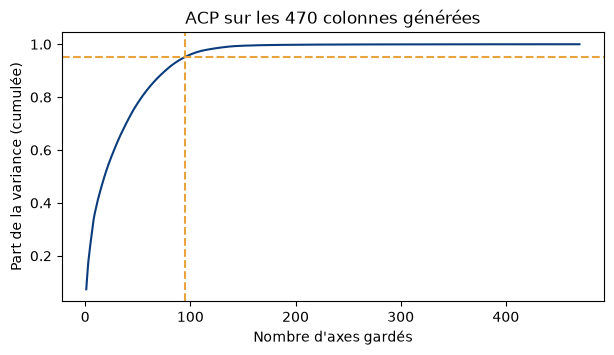

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(variance_cumulee) + 1), variance_cumulee, color="#0B3C7D")
ax.axhline(0.95, color="#E8A33D", linestyle="--")
ax.axvline(acp.n_components_, color="#E8A33D", linestyle="--")
ax.set(xlabel="Nombre d'axes gardés", ylabel="Part de la variance (cumulée)",
       title="ACP sur les 470 colonnes générées")
plt.show()

Il faut 95 axes pour garder 95 % de la variance des 470 colonnes. La courbe monte lentement : le premier axe porte
7,4 % de la variance, 10 axes 37,7 %, 50 axes 77,8 %. Puis elle plafonne : les 375 axes suivants se partagent les
5 % restants. Nous verrons plus bas ce que contiennent ces 5 %.

Les **chargements** disent quelles colonnes composent un axe (cours 2, slide 16). Voici les cinq plus forts du
premier axe :

In [9]:
chargements = pd.Series(acp.components_[0], index=Z_train.columns)
chargements[chargements.abs().sort_values(ascending=False).index[:5]].round(3)

previous_bookings_not_canceled                      0.300
is_repeated_guest previous_bookings_not_canceled    0.298
lead_time previous_bookings_not_canceled           -0.285
adults previous_bookings_not_canceled              -0.280
previous_bookings_not_canceled adr                 -0.262
dtype: float64

Ce premier axe se lit à peu près : ses cinq plus forts chargements (autour de ±0,3) font tous intervenir
`previous_bookings_not_canceled`, seule ou multipliée par une autre colonne. C'est plutôt l'exception : il ne
porte que 7,4 % de la variance, et les axes suivants mélangent des dizaines de colonnes. Un axe est rarement
interprétable seul (cours 2, slide 16).

L'ACP garde 95 % de la variance. Mais **la variance de quoi ?** Une colonne standardisée a une variance de 1 ;
une colonne one-hot dont la modalité touche une part q des réservations a une variance q(1 − q), au plus 0,25.
Faisons les comptes, bloc par bloc.

In [10]:
variances = Z_train.var()
bloc = np.where(Z_train.columns.isin(colonnes_num), "issues des numériques", "one-hot")
variances.groupby(bloc).agg(["size", "sum"]).round(1)

,size,sum
issues des numériques,119,119.0
one-hot,351,5.6


Les 119 colonnes issues des numériques pèsent 119,0 ; les 351 colonnes one-hot, 5,6 seulement, soit 4,5 % de la
variance totale (5,6 sur 124,6). C'est moins que les 5 % que l'ACP s'autorise à jeter : elle peut atteindre son
seuil de 95 % en sacrifiant presque toutes les modalités.

Vérifions-le : on projette le train sur les axes gardés, on revient dans l'espace des 470 colonnes
(`inverse_transform`), et l'on mesure, colonne par colonne, la part de sa variance qui a survécu.

In [11]:
ecart = Z_train - acp.inverse_transform(acp.transform(Z_train))
part_gardee = 1 - ecart.var() / variances
print(part_gardee.groupby(bloc).mean().round(3))
cles = ["lead_time", "hotel_City Hotel", "deposit_type_Non Refund", "agent_9", "country_PRT", "market_segment_Groups"]
pd.DataFrame({"variance": variances[cles], "part gardée par l'ACP": part_gardee[cles]}).round(3)

issues des numériques    0.975
one-hot                  0.074
dtype: float64


,variance,part gardée par l'ACP
lead_time,1.000,0.924
hotel_City Hotel,0.225,0.934
deposit_type_Non Refund,0.112,0.734
agent_9,0.187,0.686
country_PRT,0.246,0.569
market_segment_Groups,0.147,0.515


C'est bien ce qui se passe. En moyenne, l'ACP garde 97,5 % de la variance des colonnes issues des numériques, mais
7,4 % seulement de celle des colonnes one-hot. Les modalités fréquentes s'en tirent mieux que les rares, mais
`deposit_type_Non Refund` perd déjà 27 % de sa variance (elle en garde 73,4 %), `country_PRT` 43 % et
`market_segment_Groups` près de la moitié. Or ce sont justement les colonnes qui prédisent le mieux, comme le montrera le
filtre de la section 4.

> 💬 **Pour la salle.** L'ACP garde 95 % de la variance. Pourquoi ne garde-t-elle pas 95 % de ce qui sert à
> prédire l'annulation ?
>
> *Piste : l'ACP est non supervisée, elle ne regarde jamais `y` (cours 2, slide 16). Elle garde ce qui varie
> beaucoup, pas ce qui sépare les annulées des autres. Ici, ce qui varie beaucoup, ce sont les 119 colonnes
> standardisées issues des numériques ; ce qui prédit, ce sont surtout des modalités (`deposit_type`, pays,
> agents), dont la variance est petite par construction : au plus 0,25.*

## 4. Filtrer : un score par colonne

Deuxième remède : garder des colonnes d'origine. Un filtre note chaque colonne **seule**, sans modèle (cours 2,
slide 18). `f_classif` est l'ANOVA F : la moyenne de la colonne diffère-t-elle entre réservations annulées et non
annulées ? On garde les 40 meilleures.

In [12]:
filtre = SelectKBest(f_classif, k=40).fit(Z_train, y_train)
scores_f = pd.Series(filtre.scores_, index=Z_train.columns).sort_values(ascending=False)
gardees_f = Z_train.columns[filtre.get_support()]
print(len(gardees_f), "colonnes gardées, dont", gardees_f.isin(colonnes_num).sum(), "issues des numériques")
scores_f.head(10).round(0)

40 colonnes gardées, dont 16 issues des numériques


deposit_type_Non Refund       32589.0
deposit_type_No Deposit       31775.0
country_PRT                   13689.0
lead_time                     11058.0
total_of_special_requests      5751.0
market_segment_Groups          5591.0
agent_1                        4911.0
lead_time^2                    3828.0
distribution_channel_TA/TO     3017.0
market_segment_Direct          2278.0
dtype: float64

Le filtre garde 16 colonnes issues des numériques et 24 colonnes one-hot. En tête : les deux modalités de
`deposit_type` (« Non Refund », la colonne surprenante du notebook 00), le Portugal (`country_PRT`), `lead_time`,
les demandes spéciales, le segment « Groups ». Un seul terme fabriqué parmi les dix premiers : `lead_time^2`.
Mais regardez les deux premières lignes :

In [13]:
print("Corrélation :", Z_train["deposit_type_Non Refund"].corr(Z_train["deposit_type_No Deposit"]).round(3))

Corrélation : -0.993


Les deux colonnes de `deposit_type` sont corrélées à −0,993 : « No Deposit » et « Non Refund » couvrent presque
toutes les réservations, l'une est presque l'inverse de l'autre. Le filtre les garde toutes les deux, car il juge
chaque colonne seule.

> 💬 **Pour la salle.** Le filtre garde `deposit_type_Non Refund` et `deposit_type_No Deposit`. Que lui
> reprochez-vous, et que faudrait-il faire avant `SelectKBest` ?
>
> *Piste : la seconde colonne n'apporte presque rien de plus que la première, mais elle prend l'une des 40 places.
> Un filtre ne voit ni la redondance ni les interactions (le XOR de la slide 19). D'où l'ordre du cours 2
> (slide 18) : retirer les constantes, puis les redondantes (|r| > 0,9), et seulement ensuite garder les colonnes
> les plus liées à la cible.*

L'**information mutuelle** capte aussi les liens non linéaires, mais elle coûte plus cher : on la calcule sur
l'échantillon de 10 000 réservations, en signalant les colonnes one-hot comme discrètes.

In [14]:
discretes = ~echantillon.columns.isin(colonnes_num)
info_mutuelle = pd.Series(mutual_info_classif(echantillon, y_train.loc[echantillon.index],
                                              discrete_features=discretes, random_state=0), index=echantillon.columns)
print("Colonnes communes aux 40 premières des deux filtres :",
      len(set(info_mutuelle.nlargest(40).index) & set(gardees_f)))
info_mutuelle.nlargest(10).round(3)

Colonnes communes aux 40 premières des deux filtres : 12


lead_time arrival_date_day_of_month    0.157
lead_time arrival_date_week_number     0.152
deposit_type_Non Refund                0.146
lead_time adr                          0.140
deposit_type_No Deposit                0.140
lead_time total_of_special_requests    0.138
lead_time previous_cancellations       0.136
lead_time stays_in_week_nights         0.136
lead_time stays_in_weekend_nights      0.126
lead_time days_in_waiting_list         0.116
dtype: float64

Le classement change beaucoup : l'information mutuelle met en tête huit produits de `lead_time` (avec le jour du
mois, la semaine, le prix, les demandes spéciales…), qui transportent tous à peu près la même information, celle
du délai. Seules 12 colonnes sont communes aux 40 premières des deux filtres : deux scores, deux sélections, et
aucun des deux ne remarque que ses favorites se répètent.

## 5. Le piège : sélectionner avant de valider

Sélectionner, c'est **apprendre** : le filtre a regardé `y`. Il doit donc s'ajuster sur le train seulement, et
dans chaque pli d'une validation croisée. Reprenons la démonstration du cours (cours 2, slide 23) : 50
observations, 5 000 variables de **pur bruit**, un plus proche voisin, et 20 tirages.

In [15]:
erreurs = []
for tirage in range(20):
    rng = np.random.default_rng(tirage)
    X_bruit, y_bruit = rng.normal(size=(50, 5000)), rng.permutation(np.repeat([0, 1], 25))
    X_choisies = SelectKBest(f_classif, k=100).fit_transform(X_bruit, y_bruit)
    avant = cross_val_score(KNeighborsClassifier(n_neighbors=1), X_choisies, y_bruit, cv=5).mean()
    dedans = cross_val_score(make_pipeline(SelectKBest(f_classif, k=100), KNeighborsClassifier(n_neighbors=1)),
                             X_bruit, y_bruit, cv=5).mean()
    erreurs.append({"sélection avant la validation": 1 - avant, "sélection dans le pipeline": 1 - dedans})
pd.DataFrame(erreurs).agg(["mean", "min", "max"]).round(2)

,sélection avant la validation,sélection dans le pipeline
mean,0.01,0.51
min,0.00,0.38
max,0.06,0.70


Avec des variables de pur bruit, la sélection faite **avant** la validation annonce 1 % d'erreur en moyenne sur 20
tirages (0 % dans le meilleur cas, 6 % dans le pire) ; refaite **dans chaque pli**, grâce au pipeline, elle donne
51 % : le hasard, la vraie performance sur du bruit. Parmi 5 000 colonnes de bruit, certaines collent aux 50
étiquettes par pur hasard ; si la sélection a vu toutes les étiquettes, celles du pli de validation comprises, ce
sont ces colonnes-là qu'elle garde. C'est pourquoi, à la section 8, chaque réduction est une étape du pipeline :
`evaluer` l'ajuste sur le train, et le test ne la voit jamais.

## 6. Le wrapper, en démonstration

Un wrapper juge des **sous-ensembles** avec un vrai modèle (cours 2, slide 20). En sélection avant, il part de
l'ensemble vide et ajoute, à chaque étape, la colonne qui améliore le plus le score en validation croisée. Sur
470 colonnes, ce serait hors de prix ; on le montre sur les 14 numériques standardisées. `TimeSeriesSplit(3)` :
chaque pli apprend sur le passé et se valide juste après (cours 1, slide 9), ce qui suppose un train trié par
date d'arrivée, ce que fait `decouper()`.

In [16]:
sfs = SequentialFeatureSelector(LogisticRegression(max_iter=2000), n_features_to_select=5, direction="forward",
                                cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc", n_jobs=-1)
debut = time.perf_counter()
sfs.fit(Z_train[NUMERIQUES], y_train)
print(f"{time.perf_counter() - debut:.0f} s ·", (14 + 13 + 12 + 11 + 10) * 3, "entraînements")
list(sfs.get_feature_names_out())

21 s · 180 entraînements


['lead_time',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'adr',
 'total_of_special_requests']

En une vingtaine de secondes et 180 entraînements (14 + 13 + 12 + 11 + 10 sous-ensembles essayés, 3 plis chacun), le wrapper retient
`lead_time`, `previous_cancellations`, `previous_bookings_not_canceled`, `adr` et `total_of_special_requests`
(dans l'ordre des colonnes : `SequentialFeatureSelector` ne dit pas dans quel ordre il les a ajoutées). Le délai,
l'historique du client, le prix et les demandes spéciales : une liste qu'un connaisseur de l'hôtellerie aurait
pu proposer.

In [17]:
for colonnes in [NUMERIQUES, list(sfs.get_feature_names_out())]:
    auc = cross_val_score(LogisticRegression(max_iter=2000), Z_train[colonnes], y_train,
                          cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc")
    print(len(colonnes), "variables : AUC moyenne en validation croisée", auc.mean().round(3))

14 variables : AUC moyenne en validation croisée 0.737


5 variables : AUC moyenne en validation croisée 0.743


Avec 5 variables sur 14, l'AUC moyenne en validation croisée passe de 0,737 à 0,743 : les 9 autres n'apportaient
rien à ce modèle linéaire. Attention : 0,743 est mesuré sur les plis mêmes qui ont servi à choisir, il est donc un
peu optimiste. C'est le risque propre au wrapper : sur-ajuster la sélection elle-même (cours 2, slide 20).

> 💬 **Pour la salle.** Ici, 180 entraînements pour passer de 14 à 5 variables. Combien en faudrait-il pour
> choisir 40 colonnes parmi les 470 générées, avec les mêmes 3 plis ?
>
> *Piste : 470 + 469 + … + 431 = 18 020 sous-ensembles, soit 54 060 entraînements. À plusieurs secondes par
> entraînement sur 95 190 lignes, cela se compte en heures de calcul : le wrapper sert à affiner une courte liste, pas
> à trier des centaines de colonnes (cours 2, slide 22).*

## 7. Embedded : la pénalité L1

Troisième famille : sélectionner **en apprenant** (cours 2, slide 21). La pénalité L1 pousse des coefficients
exactement à zéro ; `SelectFromModel` garde les colonnes dont le coefficient n'est pas nul. `C` est l'inverse de
la force de la pénalité : plus il est petit, plus il y a de zéros. Les colonnes sont standardisées, ce que la L1
exige. `tol=1e-3` (au lieu de `1e-4`) arrête l'optimisation un peu plus tôt : une précision largement suffisante
pour décider quels coefficients sont nuls. `random_state=0` fixe l'ordre dans lequel liblinear parcourt les
données : on retrouve ainsi les mêmes colonnes à chaque exécution.

In [18]:
l1 = LogisticRegression(l1_ratio=1, solver="liblinear", C=0.05, tol=1e-3, random_state=0)
debut = time.perf_counter()
selection_l1 = SelectFromModel(l1).fit(Z_train, y_train)
gardees_l1 = Z_train.columns[selection_l1.get_support()]
print(f"{time.perf_counter() - debut:.0f} s ·", len(gardees_l1), "colonnes gardées sur", Z_train.shape[1],
      "· dont", gardees_l1.isin(colonnes_num).sum(), "issues des numériques")

13 s · 182 colonnes gardées sur 470 · dont 102 issues des numériques


En une quinzaine de secondes, la pénalité L1 garde 182 colonnes sur 470 : 102 des 119 colonnes issues des numériques, mais
seulement 80 des 351 colonnes one-hot. Ce sont donc surtout des colonnes one-hot qu'elle écarte (271 sur 351) :
des modalités dont le coefficient ne valait pas la pénalité. Elle garde en revanche la plupart des produits : à
`C=0.05`, elle reste généreuse.

In [19]:
coefficients = pd.Series(selection_l1.estimator_.coef_[0], index=Z_train.columns)
print("is_repeated_guest :", coefficients["is_repeated_guest"].round(3),
      "· is_repeated_guest^2 :", coefficients["is_repeated_guest^2"].round(3))
coefficients[gardees_l1].sort_values(key=np.abs, ascending=False).head(10).round(2)

is_repeated_guest : -0.024 · is_repeated_guest^2 : -0.072


previous_cancellations     3.73
deposit_type_Non Refund    3.35
agent_17                   1.77
agent_9                    1.76
country_PRT                1.74
agent_240                  1.52
agent_56                   1.35
agent_191                  1.29
agent_134                  1.22
deposit_type_No Deposit   -1.20
dtype: float64

Les dix plus gros coefficients sont tous des colonnes d'origine : `previous_cancellations`,
`deposit_type_Non Refund`, des agents, le Portugal. Aucun produit n'y figure. Et la L1 ne sait pas départager
deux colonnes identiques : `is_repeated_guest` et son carré gardent chacune un petit coefficient (−0,024 et
−0,072). Pour la pénalité, |a| + |b| vaut la même chose pour toutes les façons de partager un coefficient entre
deux colonnes identiques : la L1 ne retire pas les doublons à notre place.

## 8. Évaluer : trois réductions, cinq modèles

### 8.1 Deux repères, sans réduction

Pour juger une réduction, il faut savoir d'où l'on part. Deux repères, avec les deux modèles les plus rapides :
les 365 colonnes de l'approche A (sans interactions) et les 470 colonnes générées, sans réduction.

In [20]:
sans_interactions = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIQUES),
    ("cat", one_hot, CATEGORIELLES)])
reperes = []
for preparation, prep in {"365 colonnes (A)": sans_interactions, "470 colonnes générées": genere}.items():
    for nom in ["Régression logistique", "Gradient boosting"]:
        pipe = make_pipeline(clone(prep), modeles()[nom]).fit(X_train, y_train)
        reperes.append({"préparation": preparation, "modele": nom,
                        "auc": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])})
pd.DataFrame(reperes).pivot(index="préparation", columns="modele", values="auc").round(3)

modele,Gradient boosting,Régression logistique
préparation,,
365 colonnes (A),0.873,0.853
470 colonnes générées,0.869,0.845


Les 105 colonnes générées n'apportent rien : la régression logistique passe de 0,853 (365 colonnes : ce sont les
scores de l'approche A) à 0,845 avec les 470 colonnes, le boosting de 0,873 à 0,869. Les interactions
ne contiennent pas de signal que les modèles ne trouvaient pas déjà (le boosting fabrique ses propres interactions en
enchaînant les coupures) ; elles ajoutent surtout du bruit et du calcul. C'est à ces deux lignes qu'on compare les
trois réductions.

### 8.2 C1 · interactions + ACP

Chaque variante est **un seul pipeline** : génération, réduction, modèle. `evaluer` le réajuste sur le train pour
chacun des cinq modèles : l'ACP n'apprend jamais rien du test.

In [21]:
colonnes_affichees = ["modele", "auc", "precision_moyenne", "exactitude", "nb_variables", "duree_s"]
resultats_c1, _ = evaluer("C1 · interactions + ACP", make_pipeline(genere, PCA(n_components=0.95)),
                          X_train, y_train, X_test, y_test)
print(f"Durée de la variante : {resultats_c1['duree_s'].sum():.0f} s")
resultats_c1[colonnes_affichees]

Durée de la variante : 100 s


,modele,auc,precision_moyenne,exactitude,nb_variables,duree_s
0,Régression logistique,0.795,0.771,0.740,95,4.435
1,kNN,0.743,0.703,0.710,95,11.333
2,Réseau de neurones,0.819,0.787,0.750,95,24.676
3,Forêt aléatoire,0.789,0.757,0.737,95,53.531
4,Gradient boosting,0.807,0.778,0.744,95,5.986


L'ACP coûte cher : la régression logistique tombe à 0,795 (0,845 sans réduction), le boosting à 0,807 (0,869).
La forêt (0,789) et le kNN (0,743) font encore moins bien ; le réseau de neurones résiste le mieux (0,819). La
variante a pris un peu moins de deux minutes, dont environ la moitié pour la forêt seule : sur 95 axes continus, les
arbres ont beaucoup plus de seuils à essayer que sur des colonnes à 0 ou 1.

### 8.3 C2 · interactions + filtre

In [22]:
resultats_c2, _ = evaluer("C2 · interactions + filtre", make_pipeline(genere, SelectKBest(f_classif, k=40)),
                          X_train, y_train, X_test, y_test)
print(f"Durée de la variante : {resultats_c2['duree_s'].sum():.0f} s")
resultats_c2[colonnes_affichees]

Durée de la variante : 65 s


,modele,auc,precision_moyenne,exactitude,nb_variables,duree_s
0,Régression logistique,0.808,0.775,0.732,40,6.684
1,kNN,0.803,0.768,0.739,40,7.580
2,Réseau de neurones,0.815,0.783,0.742,40,38.246
3,Forêt aléatoire,0.819,0.789,0.750,40,9.249
4,Gradient boosting,0.826,0.794,0.751,40,3.282


Avec 40 colonnes, le filtre fait mieux que l'ACP pour quatre modèles sur cinq (boosting 0,826, forêt 0,819,
kNN 0,803, régression logistique 0,808), mais reste loin des repères sans réduction. En ne gardant que les 40
colonnes les plus liées à la cible une à une, il ne garde que 24 des 351 colonnes one-hot : la plupart des agents
et des pays disparaissent, alors qu'ils pèsent peu chacun mais beaucoup ensemble. Le kNN, lui, n'a jamais fait
aussi bien dans ce notebook : 40 dimensions lui conviennent mieux que 95 axes. C'est aussi la variante la plus
rapide (environ une minute).

### 8.4 C3 · interactions + L1

`SelectFromModel` est réajusté pour chacun des cinq modèles : une quinzaine de secondes de sélection à chaque fois (section 7),
avant même d'entraîner le modèle. C'est la variante la plus lente à préparer. Avec la tolérance par défaut
(`tol=1e-4`), chaque sélection prenait environ une minute lors de la préparation du TD, soit près de quatre
minutes de plus pour la variante : d'où `tol=1e-3`, qui donne la même sélection à quelques colonnes près.

In [23]:
resultats_c3, _ = evaluer("C3 · interactions + L1", make_pipeline(genere, SelectFromModel(l1)),
                          X_train, y_train, X_test, y_test)
print(f"Durée de la variante : {resultats_c3['duree_s'].sum():.0f} s")
resultats_c3[colonnes_affichees]

Durée de la variante : 185 s


,modele,auc,precision_moyenne,exactitude,nb_variables,duree_s
0,Régression logistique,0.845,0.808,0.756,182,28.874
1,kNN,0.762,0.725,0.720,182,30.632
2,Réseau de neurones,0.850,0.813,0.762,182,62.762
3,Forêt aléatoire,0.837,0.804,0.763,182,38.823
4,Gradient boosting,0.867,0.829,0.770,182,23.442


Avec 182 colonnes, la sélection L1 garde l'essentiel : la régression logistique obtient 0,845 et le boosting 0,867,
presque exactement les scores des 470 colonnes sans réduction (0,845 et 0,869), avec 2,6 fois moins de colonnes.
Le réseau de neurones monte à 0,850, la forêt à 0,837. Le kNN reste à la traîne (0,762) : 182 dimensions, c'est
encore beaucoup pour des distances. Le prix : environ trois minutes, la variante la plus lente,
dont une quinzaine de secondes de sélection pour chaque modèle.

## 9. Lire les résultats

On rassemble les trois variantes : l'AUC de chaque modèle, le nombre de colonnes que reçoit le modèle et la durée
totale de la variante.

In [24]:
resultats = pd.concat([resultats_c1, resultats_c2, resultats_c3])
tableau = resultats.pivot(index="approche", columns="modele", values="auc")[list(modeles())]
tableau["colonnes"] = resultats.groupby("approche")["nb_variables"].first()
tableau["durée (s)"] = resultats.groupby("approche")["duree_s"].sum().round(0)
tableau

modele,Régression logistique,kNN,Réseau de neurones,Forêt aléatoire,Gradient boosting,colonnes,durée (s)
approche,,,,,,,
C1 · interactions + ACP,0.795,0.743,0.819,0.789,0.807,95,100.0
C2 · interactions + filtre,0.808,0.803,0.815,0.819,0.826,40,65.0
C3 · interactions + L1,0.845,0.762,0.850,0.837,0.867,182,185.0


La sélection L1 est la plus chère (colonne « durée » : environ trois minutes, contre moins de deux pour l'ACP et
une pour le filtre), parce qu'elle réapprend une régression logistique pénalisée avant chaque modèle. Côté AUC, la ligne C3 l'emporte partout, sauf pour
le kNN ; le graphique met les cinq modèles côte à côte.

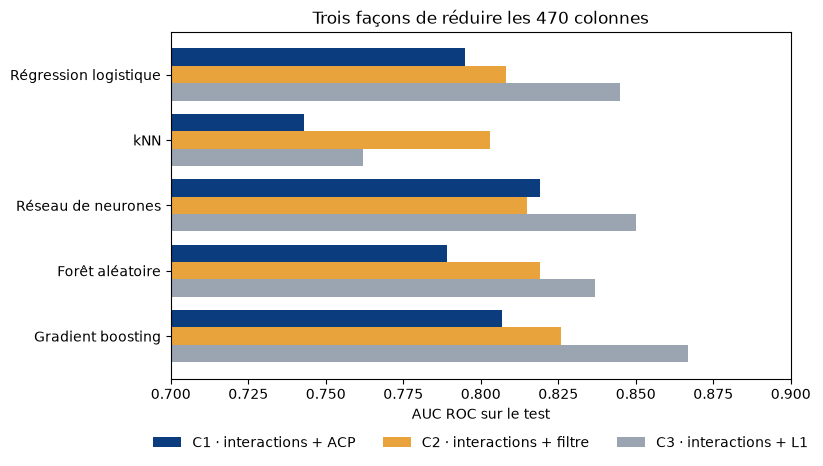

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
tableau[list(modeles())].T.plot.barh(ax=ax, color=["#0B3C7D", "#E8A33D", "#9AA5B1"], width=0.8)
ax.set(xlim=(0.7, 0.9), xlabel="AUC ROC sur le test", ylabel="", title="Trois façons de réduire les 470 colonnes")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
plt.show()

Trois lectures, en suivant les familles de modèles de la fiche réflexe (cours 2, slide 28) :

- **La sélection L1 (C3) arrive en tête pour quatre modèles sur cinq** : régression logistique 0,845, réseau de
  neurones 0,850, forêt 0,837, boosting 0,867. Elle retrouve le niveau des 470 colonnes sans réduction : réduire
  n'a rien coûté, et chaque modèle reçoit 182 colonnes au lieu de 470.
- **Le kNN préfère le filtre (C2)** : 0,803 avec 40 colonnes, contre 0,762 avec 182 colonnes et 0,743 avec 95
  axes. Pour un modèle fondé sur des distances, avoir peu de dimensions compte davantage que garder chaque détail
  (cours 2, slide 11).
- **L'ACP (C1) est dernière pour quatre modèles sur cinq** ; seul le réseau de neurones y fait un peu mieux
  qu'avec le filtre (0,819 contre 0,815).

### Pourquoi l'ACP fait-elle perdre tous les modèles ?

Par rapport aux 470 colonnes sans réduction, l'ACP coûte 0,050 d'AUC à la régression logistique (0,795 contre
0,845) et 0,062 au boosting (0,807 contre 0,869) ; elle est derrière la sélection L1 pour les cinq modèles. Trois
raisons, toutes visibles à la section 3 :

1. **Elle est non supervisée.** Elle cherche les directions où les données varient le plus, sans jamais regarder
   `y`. Garder 95 % de la variance, ce n'est pas garder 95 % du signal (cours 2, slide 16).
2. **Les colonnes one-hot ne pèsent presque rien dans la variance.** Une colonne standardisée pèse 1, une colonne
   de 0 et de 1 au plus 0,25 : les 351 colonnes one-hot ne font que 5,6 sur 124,6, soit 4,5 %. L'ACP atteint ses
   95 % en les sacrifiant presque toutes (7,4 % de leur variance gardée en moyenne), et avec elles les agents,
   les pays et une partie de `deposit_type`, les colonnes les plus prédictives. Elle conserve au contraire 97,5 %
   de la variance des 119 colonnes issues des numériques, dont les 105 carrés et produits qui n'apportaient rien
   (section 8.1).
3. **Les axes mélangent tout.** Chaque axe combine des dizaines de colonnes. Un arbre, qui isolait « Non Refund »
   d'une seule coupure, doit maintenant couper sur des mélanges : la forêt passe de 0,837 (C3) à 0,789, le
   boosting de 0,867 à 0,807.

L'ACP n'est pas mauvaise en soi : sur des colonnes de même nature et de même échelle, comme les 64 pixels de la
démonstration du cours (cours 2, slide 15), elle résume très bien. Ici, elle mélange 119 colonnes continues
standardisées et 351 colonnes de 0 et de 1 : une fois de plus, c'est l'échelle qui décide de ce qui compte.

> 💬 **Pour la salle.** Générer toutes les interactions puis laisser la réduction trier, ou formuler des
> hypothèses comme dans l'approche B : que retenez-vous de ce notebook ?
>
> *Piste : ici, les 105 colonnes générées n'ont rien apporté (0,845 contre 0,853 pour la régression logistique)
> et ont coûté du calcul à chaque étape. `PolynomialFeatures` ne fabrique que des produits de colonnes
> existantes : il n'inventera jamais le taux d'annulation passé d'un agent, qui demande une idée et une jointure
> dans le temps. Générer peut dépanner quand on connaît mal le domaine, à condition de réduire ensuite avec une
> méthode supervisée (la L1), dans le pipeline. Le notebook 05 met les quatre approches côte à côte.*

## À retenir

- **Générer sans hypothèse est facile, et ça explose vite** : 14 numériques donnent 119 colonnes ; croiser aussi
  les one-hot en donnerait 67 160 (51 Go). Ici, les 105 colonnes générées n'ont rien apporté : 0,845 contre 0,853
  pour la régression logistique, 0,869 contre 0,873 pour le boosting.
- **L'ACP n'est pas supervisée** : 95 % de la variance n'est pas 95 % du signal. Les colonnes one-hot (4,5 % de
  la variance) y sont sacrifiées, et tous les modèles reculent (régression logistique 0,795, boosting 0,807).
- **Un filtre juge chaque colonne seule** : il est rapide (environ une minute pour la variante), mais aveugle à la redondance
  (les deux colonnes de `deposit_type`, r = −0,993) et aux interactions ; avec 40 colonnes, il plafonne à 0,826.
  Le kNN, qui a besoin de peu de dimensions, y trouve pourtant son meilleur score (0,803).
- **La pénalité L1 garde l'essentiel** : 182 colonnes sur 470, et les scores des 470 colonnes (0,845 pour la
  régression logistique, 0,867 pour le boosting). Le wrapper, lui, reste une démonstration : 180 entraînements
  pour choisir 5 colonnes parmi 14.
- **Toute réduction apprend, donc elle va dans le pipeline** : sur du pur bruit, sélectionner avant de valider
  annonce 1 % d'erreur, contre 51 % en réalité.